# Hartland Quay (Devon) — LDI fit

One diffeomorphic **restore** event fitted to the bedding and the traces that
`05a_hartland_quay_data` cleaned and picked, built around the fold axis 05a
decided from the stereonet. An ensemble of fits shares one set of settings; the members
differ only by the Fourier seed. Member 0 is the fit used for the diagnostics below,
the meshes and the figures.

**Why this example.** The coastal section is tightly folded, and the traces are
not correlated, so their stratigraphic order is unknown. Restore represents
lithology as a flat layer-cake pulled back through a volume-preserving flow, so
contacts restore to original horizontality rather than closing into bubbles.

**Training.** The energy-biased scheme of the other examples: energy-normalised
cubic modes, amplitudes started at zero and trained by plain SGD (momentum),
phases and biases trained by Adam. `ENERGY_BIASED = False` restores the earlier
Adam-only fit.

**What this notebook is.** Computation and quick checks; the plots are not
saved. Saved to `results/`:

- `inputs.npz` — the traces, bedding, cloud, hinge and the evaluation grid (read
  by `05c_hartland_quay_surfe`, so Surfe runs on the same grid, and by the figures);
- `ldi.npz` — restored depth on the grid, the isovalue and restored depth of each
  trace, the restored traces, critical points and the younging angles, and
  member 0's well-spread beds (`bed_names`, `bed_isovalues`, `bed_trace_index`);
- `beds.npz` — the same beds on their own, written when the lithology cell runs:
  the fitted traces chosen for the meshes and the render, oldest first;
- `ldi.json` — the comparison numbers; `fit_settings.json`; `restore.pt` (member 0,
  meshed by `05d_hartland_quay_meshes`);
- `ensemble/member_00.pt` onwards — every member, `member_00.pt` the same fit as
  `restore.pt`; `ensemble/metrics.npz` and `ensemble/ensemble.json` — each member's
  error metrics and the spread across the ensemble.

## Setup

In [1]:
import json
import random
from pathlib import Path

import numpy as np
import torch
import matplotlib.pyplot as plt

import curlew
from curlew.core import CSet, HSet
from curlew.geometry import Grid
from curlew.geology import restore
from curlew.kinematics.euler import euler_velocity
from curlew.priors.spectral import spectral_band, n_features_for_band
from curlew.io import loadModel, saveModel

import sys
sys.path.insert(0, str(Path("..").resolve()))  # publication/: figstyle, diagnostics, exploded3d
import figstyle
import diagnostics
import hartland_inputs  # the processed data from 05a
figstyle.apply()

curlew.device = "cuda" if torch.cuda.is_available() else "cpu"
curlew.dtype = torch.float32
curlew.default_dim = 3

SEED = 404
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

OUT_DIR = hartland_inputs.RESULTS_DIR
OUT_DIR.mkdir(parents=True, exist_ok=True)
print(f"device={curlew.device}, dtype={curlew.dtype}")

device=cpu, dtype=torch.float32


## Data and constraints

The kept, thinned traces and the cleaned bedding from 05a, in the modelling
frame. Each trace is an equality constraint of its own: the traces are distinct
beds whose stratigraphic order is not known, so there is no `iq` term. `hinge`
is the π-axis of all bedding, chosen in 05a.

In [2]:
data = hartland_inputs.load_processed()
traces, trace_names = data["traces"], data["trace_names"]
gp, gv, hinge = data["gp_fit"], data["gv_fit"], data["hinge"]
cloud_xyz, cloud_rgb = data["cloud_xyz"], data["cloud_rgb"]
origin = data["origin"]
axis = data["settings"]["axes"]["all"]

C = CSet(gp=gp, gv=gv, eq=[t.astype(np.float32) for t in traces])
print(f"{len(traces)} traces ({sum(len(t) for t in traces)} points), "
      f"{len(gp)} bedding for the fit, {len(data['gp_test'])} bedding held out | "
      f"hinge trend {axis['trend']:.1f}°, plunge {axis['plunge']:.1f}°")

130 traces (2724 points), 147 bedding for the fit, 20 bedding held out | hinge trend 78.7°, plunge 5.8°


## Evaluation grid

The cloud's extent with a 20 m pad, at 5 m (2 m vertically). The pin is the
centre of the grid. The inputs and the grid are saved now, so Surfe can run on
exactly this grid.

In [3]:
PAD = 20.0
lo, hi = cloud_xyz.min(0), cloud_xyz.max(0)
centre = 0.5 * (lo + hi)
centre[0] = float(cloud_xyz[:, 0].mean())
G = Grid(tuple(float(v) for v in hi - lo + 2 * PAD), step=(5.0, 5.0, 5.0), center=tuple(centre.tolist()),
         sampleArgs=dict(N=128))
domaxes = G.tformed_axes
anchor = torch.tensor(centre, dtype=curlew.dtype, device=curlew.device)
print("grid", G.shape, "step", G.step)

np.savez_compressed(
    OUT_DIR / "inputs.npz",
    horizon_names=np.asarray(trace_names), **{f"horizon_{i}": t for i, t in enumerate(traces)},
    gp=gp, gv=gv, origin=origin, hinge=hinge,
    cloud_xyz=cloud_xyz.astype(np.float32), cloud_rgb=(cloud_rgb * 255).round().astype(np.uint8),
    x=np.asarray(domaxes[0], dtype=float), y=np.asarray(domaxes[1], dtype=float), z=np.asarray(domaxes[2], dtype=float),
)
print("wrote", OUT_DIR / "inputs.npz")

grid (64, 91, 27) step (5.0, 5.0, 5.0)
wrote results/inputs.npz


## Restore

The velocity is an Euler pair around the hinge: α is a cubic random Fourier
field with wavevectors in all three dimensions (not `cylindrical`), and β is the
distance along the hinge, so material moves in fold profiles, and the profiles
can change along the hinge (the folds are not cylindrical). Its wavelength band is read
from the constraints (`curlew.priors.spectral.spectral_band`), in the profile
perpendicular to the hinge: *L*min is the shorter of the hinge spacing 2π√(*m*₂/*m*₄)
and the limb spacing 2π√(*m*₀/*m*₂); *L*max the longer, and at least two octaves above
*L*min and the data's diameter. The mode count follows from the band at a fixed
number of modes per octave. The bedding normals lie near a great circle. Their orientation
tensor is treated as Surfe treats it for its global anisotropy: the long axis is the
smallest eigenvector, and the other two axes are stretched by the square root of their
eigenvalue ratios. Those ratios divide the wavenumbers, and they are scaled so the
smallest length-scale multiplier is 1. The drawn band is that shortest wavelength, and
the pole is longer by the ratio of the largest eigenvalue to the smallest. The
scalar is restored depth φ(*x*) = (Φ⁻¹*x*)[*z*]; bedding is matched after Nanson
transport. `eq_sample` draws a few points from each trace at every step, so the
dense digitisation does not dominate. A weak `OrthogonalThickness` prior keeps
layers of even thickness. The cell below sets the band, the training and the seeds.
The ensemble that follows fits every member with those settings, and member 0 is the
fit the rest of this notebook uses.

In [4]:
# The wavelength band, read off the data's spectral moments (curlew.priors.spectral.spectral_band):
# contacts give the variance of horizon heights, bedding the variance of slopes, neighbouring
# bedding the variance of curvatures, measured in the profile plane (the hinge projected out).
# L_min is the shorter of the hinge spacing 2π√(m2/m4) and the limb spacing 2π√(m0/m2); L_max the
# longer, and at least two octaves above L_min and the data's diameter. The mode count follows
# from the band at a fixed number of modes per octave.
MODES_PER_OCTAVE = 128
N_DIRECTIONS = 64
LSR, BAND_INFO = spectral_band(C, axis=hinge, return_info=True)
N_FEATURES = n_features_for_band(LSR, MODES_PER_OCTAVE, N_DIRECTIONS)
print(f"band {LSR[0]:.0f}-{LSR[1]:.0f} m | M {N_FEATURES} |", BAND_INFO)
N_STEPS = 0
INTEGRATOR = "shear"
EPOCHS = 2000
WEIGHTS = dict(grad_loss="1.", eq_loss="0.1")
ANISOTROPY = False

ENERGY_BIASED = True
LR_ADAM = 5e-3          # Adam rate (phases and biases; everything if not energy-biased)
LR_SGD = 1e-1            # SGD rate for the amplitudes
AMP_MOMENTUM = 0.9
INIT_STD = 0.0 if ENERGY_BIASED else 1e-4

# Surfe's global anisotropy (RBFKernel::get_global_anisotropy), from the bedding the
# fit uses. The long axis is the smallest eigenvector, and the other two axes are
# stretched by √(λ/λmin). Those ratios divide the wavenumbers, and are scaled so the
# smallest length-scale multiplier is 1: the drawn band is the shortest wavelength,
# and the pole is longer. The same stretch is applied to every member's bank.
cov = gv.T @ gv
evals, evecs = np.linalg.eigh(cov)
evals = evals.copy()
evals[:2] = np.maximum(evals[:2], 1e-4)          # Surfe's floor on the two smaller eigenvalues
stretches = np.sqrt(evals / evals[0])            # 1 along the pole, √(λ/λmin) on the other axes
scale = stretches.max() / stretches              # length-scale multipliers; the smallest is 1
wave = 1.0 / scale                               # applied to the wavenumbers
POLE_WAVELENGTH = float(scale[0])
metric = evecs @ np.diag(wave) @ evecs.T
assert np.isclose(scale.min(), 1.0)
print(f"Surfe anisotropy: wavenumber multipliers {', '.join(f'{w:.3f}' for w in wave)}; "
      f"length-scale multipliers {', '.join(f'{s:.3f}' for s in scale)}")
print("LSR after rescaling, along each eigenvector (smallest eigenvalue first): "
      + ", ".join(f"{LSR[0] * s:.0f}-{LSR[1] * s:.0f} m" for s in scale))

# Member 0 is SEED, the fit the rest of the notebook uses. The other seeds are drawn
# once, so a re-run repeats the same ensemble.
N_ENSEMBLE = 20
ensemble_rng = np.random.default_rng(SEED + 91)
extra = []
while len(extra) < N_ENSEMBLE - 1:
    draw = int(ensemble_rng.integers(0, 2**31 - 1))
    if draw != int(SEED) and draw not in extra:
        extra.append(draw)
ENSEMBLE_SEEDS = np.array([int(SEED), *extra], dtype=np.int64)
print(f"{N_ENSEMBLE} members; member 0 seed {int(ENSEMBLE_SEEDS[0])}")

/Users/kamath92/anaconda3/envs/curlew_dev/lib/python3.11/site-packages/IPython/core/interactiveshell.py:3701: UserWarning: CSet has crs='global'; spectral_band assumes positions are already in the coordinate system used for fitting. When a GeoModel transform applies, call CSet.to_model(T) or bind through the model first.
  exec(code_obj, self.user_global_ns, self.user_ns)
/Users/kamath92/Documents/Work/2026/DevOps/curlew/curlew/priors/spectral.py:863: UserWarning: CSet has crs='global'; spectral_band assumes positions are already in the coordinate system used for fitting. When a GeoModel transform applies, call CSet.to_model(T) or bind through the model first.
  mom = spectral_moments(data, axis=axis, orientations_only=orientations_only, prefer_longer=prefer_longer)


band 51-476 m | M 448 | {'m0': 9.986017702026691, 'm2': 1.453280165802231, 'm4': 0.022450271181521732, 'lambda_x': 50.55262897816973, 'lambda_0': None, 'normal': [0.2108128321921312, -0.6988408427456286, 0.6835052496460521], 'normal_from_contacts': True, 'resolved': True, 'lambda_x_error': 0.4427219558432831, 'n_curvature': 406.8657061720138, 'window': 10.862892757313839, 'contact_noise': 0.28764229914243306, 'n_eff': 1.0, 'n_bedding': 147, 'n_contacts': 2724, 'n_pairs': 185, 'n_windows': 563, 'n_horizons_spanning': 3, 'profile': True, 'diameter': 475.9814663637141, 'curvature_modes': None, 'orientations_only': False, 'strain': None}
Surfe anisotropy: wavenumber multipliers 0.170, 0.882, 1.000; length-scale multipliers 5.868, 1.133, 1.000
LSR after rescaling, along each eigenvector (smallest eigenvalue first): 297-2793 m, 57-540 m, 51-476 m
20 members; member 0 seed 404


/Users/kamath92/Documents/Work/2026/DevOps/curlew/curlew/priors/spectral.py:729: UserWarning: horizon heights are under-sampled relative to λx; λ0 was dropped (L_min uses λx only).
  _warn_moment_quality(pick, stacklevel=2)


## Ensemble

Each member is the fit defined above, with its own Fourier seed. Member 0 uses
`SEED`, and it is the model the diagnostics, the plots and `restore.pt` use. The
error metrics below — restored-depth scatter, younging on the fitted and the held-out
bedding, flatness of the two test traces, and interior extrema — are computed for
every member. Each model is saved as it finishes.


In [5]:
def _stretch_bank(velocity):
    # freq_scaling is |Ω|², so the ||Ω|| weight is rebuilt after the wavenumbers move.
    fsf = velocity.alpha
    M = torch.as_tensor(metric, dtype=fsf.omega_spatial.dtype, device=fsf.omega_spatial.device)
    drawn = fsf.fourier_projection[:3].detach().T.clone()
    with torch.no_grad():
        fsf.fourier_projection[:3].copy_((drawn @ M).T)
        fsf.freq_scaling.copy_(fsf.fourier_projection.pow(2).sum(0).clamp(min=1e-8))
    fsf._build_derived_buffers()
    for i, w in enumerate(wave):
        e = torch.as_tensor(evecs[:, i], dtype=drawn.dtype, device=drawn.device)
        assert torch.allclose(fsf.omega_spatial @ e, (drawn @ e) * float(w), rtol=1e-4, atol=1e-5)


def fit_member(seed, name):
    seed = int(seed)
    random.seed(seed)
    np.random.seed(seed % (2**32))
    torch.manual_seed(seed)
    velocity = euler_velocity(
        3, n_features=N_FEATURES, n_directions=N_DIRECTIONS, length_scale_range=LSR,
        stream="alpha", activation="cubic", seed=seed, hinge=hinge,
        energy_normalised=ENERGY_BIASED,
    )
    if ANISOTROPY:
        _stretch_bank(velocity)
    kwargs = dict(
        C=C, H=HSet().zero(**WEIGHTS), velocity=velocity,
        n_steps=N_STEPS, integrator=INTEGRATOR, depth_axis=2,
        init_std=INIT_STD, sigma_floor=0.0, signed_normals=True, learning_rate=LR_ADAM,
        pin=anchor, collinear=True,
    )
    if ENERGY_BIASED:
        kwargs["optimizer"] = {
            "amplitude": (torch.optim.SGD, dict(lr=LR_SGD, momentum=AMP_MOMENTUM, nesterov=True)),
            "shape": (torch.optim.Adam, dict(lr=LR_ADAM)),
        }
    event = restore(name, **kwargs)
    for trace_name, t in zip(trace_names, traces):
        event.addIsosurface(trace_name, seed=t)
    model = curlew.GeoModel([event])
    model.prefit(epochs=EPOCHS, vb=True, early_stop=None, best=True)
    return model, event


def _younging(field, points, normals):
    with torch.no_grad():
        pred = field.predict_normals(
            torch.as_tensor(points, dtype=curlew.dtype, device=curlew.device)).cpu().numpy()
    obs = normals / np.linalg.norm(normals, axis=1, keepdims=True)
    pred = pred / np.linalg.norm(pred, axis=1, keepdims=True).clip(min=1e-12)
    cos = np.clip((obs * pred).sum(1), -1.0, 1.0)
    angle = np.degrees(np.arctan2(np.linalg.norm(np.cross(obs, pred), axis=1), cos))
    return angle, cos


heldout_names, heldout = hartland_inputs.heldout_traces(data)
gp_test, gv_test = data["gp_test"], data["gv_test"]


def score_member(event):
    field = event.field
    pts = lambda t: torch.as_tensor(t, dtype=curlew.dtype, device=curlew.device)
    with torch.no_grad():
        depth_std = np.array([float(field.inverse_map(pts(t))[:, 2].std()) for t in traces])
        held_sd = np.array([float(field.inverse_map(pts(t))[:, 2].std()) for t in heldout])
    young, cos = _younging(field, gp, gv)
    young_t, cos_t = _younging(field, gp_test, gv_test)

    def value_and_gradient(points):
        with torch.no_grad():
            v, g = field.value_and_gradient(pts(points))
        return v.cpu().numpy().ravel(), g.cpu().numpy()

    crit = diagnostics.find_critical_points(event, *domaxes)
    counts = np.array([int(crit.counts.get(k, 0))
                       for k in ("maximum", "minimum", "saddle", "degenerate")])
    return dict(
        depth_std=depth_std,
        younging_median=float(np.median(young)), younging_p90=float(np.percentile(young, 90)),
        younging_reversed=float(np.mean(cos < 0)),
        younging_test_median=float(np.median(young_t)), younging_test_p90=float(np.percentile(young_t, 90)),
        younging_test_reversed=float(np.mean(cos_t < 0)),
        heldout_depth_std=held_sd,
        flatness_median=float(np.median(hartland_inputs.trace_flatness(value_and_gradient, traces))),
        heldout_flatness=hartland_inputs.trace_flatness(value_and_gradient, heldout),
        extrema=counts,
    )


ENS_DIR = OUT_DIR / "ensemble"
ENS_DIR.mkdir(parents=True, exist_ok=True)
scored = []
for i, seed in enumerate(ENSEMBLE_SEEDS):
    name = "hartland_restore" if i == 0 else f"hartland_ensemble_{i:02d}"
    model, event = fit_member(seed, name)
    s = score_member(event)
    saveModel(ENS_DIR / f"member_{i:02d}.pt", model)
    scored.append(s)
    print(f"member {i + 1:02d}/{N_ENSEMBLE} seed {int(seed)}: restored-depth sd median "
          f"{np.median(s['depth_std']):.2f} m, younging {s['younging_median']:.1f}° "
          f"(held-out bedding {s['younging_test_median']:.1f}°), "
          f"interior extrema {int(s['extrema'][:2].sum())}")
    if i == 0:
        model_restore, event_restore = model, event
    else:
        del model, event
        if torch.cuda.is_available():
            torch.cuda.empty_cache()

depth_std_ens = np.stack([s["depth_std"] for s in scored])
younging_median = np.array([s["younging_median"] for s in scored])
younging_p90 = np.array([s["younging_p90"] for s in scored])
younging_reversed = np.array([s["younging_reversed"] for s in scored])
younging_test_median = np.array([s["younging_test_median"] for s in scored])
younging_test_p90 = np.array([s["younging_test_p90"] for s in scored])
younging_test_reversed = np.array([s["younging_test_reversed"] for s in scored])
heldout_depth_std_ens = np.stack([s["heldout_depth_std"] for s in scored])
flatness_median = np.array([s["flatness_median"] for s in scored])
heldout_flatness_ens = np.stack([s["heldout_flatness"] for s in scored])
extrema = np.stack([s["extrema"] for s in scored])


def _span(a, digits, unit=""):
    a = np.asarray(a, float)
    return (f"median {np.median(a):.{digits}f}{unit}, "
            f"members {np.percentile(a, 10):.{digits}f}–{np.percentile(a, 90):.{digits}f}{unit}")


print(f"across {N_ENSEMBLE} members")
print(f"  restored-depth sd, median over the fitted traces: {_span(np.median(depth_std_ens, 1), 2, ' m')}")
print(f"  younging, fitted bedding: {_span(younging_median, 1, '°')}")
print(f"  younging, held-out bedding: {_span(younging_test_median, 1, '°')}")
print(f"  flatness, fitted traces: {_span(flatness_median, 2, ' m')}")
for j, name in enumerate(heldout_names):
    print(f"  {name}: restored-depth sd {_span(heldout_depth_std_ens[:, j], 2, ' m')}, "
          f"flatness {_span(heldout_flatness_ens[:, j], 2, ' m')}")
print(f"  members with an interior extremum: {int((extrema[:, :2].sum(1) > 0).sum())} of {N_ENSEMBLE}")

np.savez_compressed(
    ENS_DIR / "metrics.npz",
    seeds=ENSEMBLE_SEEDS, trace_names=np.asarray(trace_names), heldout_names=np.asarray(heldout_names),
    depth_std=depth_std_ens, younging_median=younging_median, younging_p90=younging_p90,
    younging_reversed=younging_reversed, younging_test_median=younging_test_median,
    younging_test_p90=younging_test_p90, younging_test_reversed=younging_test_reversed,
    heldout_depth_std=heldout_depth_std_ens, flatness_median=flatness_median,
    heldout_flatness=heldout_flatness_ens,
    extrema_maximum=extrema[:, 0], extrema_minimum=extrema[:, 1],
    extrema_saddle=extrema[:, 2], extrema_degenerate=extrema[:, 3],
)
(ENS_DIR / "ensemble.json").write_text(json.dumps({"n_ensemble": N_ENSEMBLE,
    "seeds": ENSEMBLE_SEEDS.tolist(), "member_0": int(ENSEMBLE_SEEDS[0])}, indent=1))
print("wrote", ENS_DIR)


L=0.005 grad_loss=0.002 eq_loss=0.003: : 2000/2000|


member 01/20 seed 404: restored-depth sd median 0.57 m, younging 1.6° (held-out bedding 19.1°), interior extrema 0


L=0.006 grad_loss=0.002 eq_loss=0.004: : 2000/2000|


member 02/20 seed 35034316: restored-depth sd median 0.59 m, younging 1.5° (held-out bedding 17.4°), interior extrema 0


L=0.005 grad_loss=0.001 eq_loss=0.003: : 2000/2000|


member 03/20 seed 1318916082: restored-depth sd median 0.59 m, younging 1.6° (held-out bedding 16.7°), interior extrema 0


... (30 outputs left out)

L=0.005 grad_loss=0.002 eq_loss=0.003: : 2000/2000|


member 19/20 seed 456463966: restored-depth sd median 0.59 m, younging 1.4° (held-out bedding 17.3°), interior extrema 0


L=0.005 grad_loss=0.001 eq_loss=0.003: : 2000/2000|


member 20/20 seed 1773101392: restored-depth sd median 0.59 m, younging 1.5° (held-out bedding 13.9°), interior extrema 0
across 20 members
  restored-depth sd, median over the fitted traces: median 0.59 m, members 0.54–0.63 m
  younging, fitted bedding: median 1.6°, members 1.5–1.7°
  younging, held-out bedding: median 17.6°, members 14.6–20.8°
  flatness, fitted traces: median 0.62 m, members 0.58–0.66 m
  H22+H25: restored-depth sd median 8.47 m, members 5.72–10.02 m, flatness median 7.77 m, members 4.93–9.72 m
  H1+H7: restored-depth sd median 7.36 m, members 4.97–10.58 m, flatness median 5.35 m, members 3.91–6.75 m
  members with an interior extremum: 0 of 20
wrote results/ensemble


## Diagnostics

Member 0 only; the same measures across the ensemble are printed above.

- **restored traces**: each trace pulled back through Φ⁻¹ should collapse to one
  restored depth; its standard deviation is the misfit in metres;
- **younging**: the angle between the observed bedding normal and the one the
  restore predicts at the same point (over 90° is a reversed way-up);
- **critical points** of φ in the volume (Brouwer degree on the voxels, Newton
  refinement); a diffeomorphic restore of a layer-cake should have no interior
  extrema.

In [6]:
field = event_restore.field
with torch.no_grad():
    restored = [field.inverse_map(torch.as_tensor(t, dtype=curlew.dtype, device=curlew.device)).cpu().numpy()
                for t in traces]
    n_pred = field.predict_normals(torch.as_tensor(gp, dtype=curlew.dtype, device=curlew.device)).cpu().numpy()
depth_mean = np.array([r[:, 2].mean() for r in restored])
depth_std = np.array([r[:, 2].std() for r in restored])

obs = gv / np.linalg.norm(gv, axis=1, keepdims=True)
pred = n_pred / np.linalg.norm(n_pred, axis=1, keepdims=True).clip(min=1e-12)
cos = np.clip((obs * pred).sum(1), -1.0, 1.0)
younging = np.degrees(np.arctan2(np.linalg.norm(np.cross(obs, pred), axis=1), cos))
crit = diagnostics.find_critical_points(event_restore, *domaxes)

print(f"restored-depth std per trace: median {np.median(depth_std):.2f} m, max {depth_std.max():.2f} m")
print(f"younging angle: median {np.median(younging):.1f}°, mean {younging.mean():.1f}°, "
      f"reversed {np.mean(cos < 0):.2f}")
print("critical points:", crit.counts)

# Bedding misfit on the cliff and on the beach (wave-cut platform), where the two axes differ.
on_beach = data["on_beach_fit"]
younging_cliff, younging_beach = younging[~on_beach], younging[on_beach]
print(f"younging angle, fitted, cliff ({len(younging_cliff)}): median {np.median(younging_cliff):.1f}°, "
      f"90th pct {np.percentile(younging_cliff, 90):.1f}° | beach ({len(younging_beach)}): "
      f"median {np.median(younging_beach):.1f}°, 90th pct {np.percentile(younging_beach, 90):.1f}°")

gp_test, gv_test = data["gp_test"], data["gv_test"]
with torch.no_grad():
    n_test = field.predict_normals(torch.as_tensor(gp_test, dtype=curlew.dtype, device=curlew.device)).cpu().numpy()
obs_t = gv_test / np.linalg.norm(gv_test, axis=1, keepdims=True)
pred_t = n_test / np.linalg.norm(n_test, axis=1, keepdims=True).clip(min=1e-12)
cos_t = np.clip((obs_t * pred_t).sum(1), -1.0, 1.0)
younging_test = np.degrees(np.arctan2(np.linalg.norm(np.cross(obs_t, pred_t), axis=1), cos_t))
print(f"younging angle, held-out bedding ({len(gp_test)}): median {np.median(younging_test):.1f}°, "
      f"90th pct {np.percentile(younging_test, 90):.1f}°, reversed {np.mean(cos_t < 0):.2f}")

# How far the hinge bends: the angle between the local hinge (∇ of the fixed potential) and
# the π-axis, over the photographed outcrop. Zero everywhere for a straight hinge.
pts = torch.as_tensor(cloud_xyz[::20], dtype=curlew.dtype, device=curlew.device)
with torch.no_grad():
    local = field.velocity.hinge.gradient_raw(pts).cpu().numpy()
local /= np.linalg.norm(local, axis=1, keepdims=True)
bend = np.degrees(np.arccos(np.clip(np.abs(local @ hinge), 0.0, 1.0)))
z_beach = data["settings"]["z_beach"] - origin[2]
low = cloud_xyz[::20, 2] <= z_beach
print(f"hinge bend from the π-axis: median {np.median(bend):.1f}°, 95th pct {np.percentile(bend, 95):.1f}°, "
      f"max {bend.max():.1f}° | cliff median {np.median(bend[~low]):.1f}°, beach median {np.median(bend[low]):.1f}°")

restored-depth std per trace: median 0.53 m, max 2.08 m
younging angle: median 1.6°, mean 2.0°, reversed 0.00
critical points: {'maximum': 0, 'minimum': 0, 'saddle': 0, 'degenerate': 0}
younging angle, fitted, cliff (53): median 2.0°, 90th pct 4.0° | beach (94): median 1.5°, 90th pct 3.4°
younging angle, held-out bedding (20): median 19.1°, 90th pct 65.0°, reversed 0.00
hinge bend from the π-axis: median 0.0°, 95th pct 0.0°, max 0.0° | cliff median 0.0°, beach median 0.0°


## Where the surfaces land

The left-hand column is member 0's lithology. Its surfaces are `N_BEDS` of the
fitted traces, chosen so their restored depths sit nearest equal shares of the
cloud scalar, and paired so the assignment does not cross. The right-hand column
is the Shannon entropy, in bits, of the traces held out of the fit. Those two
surfaces are the same on every member, and the entropy is high where the members
put one of them on different sides of a point.


In [7]:
# Member 0's lithology uses N_BEDS fitted traces spread through the cloud.
# The entropy uses the traces held out of the fit, the same ones on every member.
N_BEDS = 12

def _spread(depths, targets):
    """Trace indices paired, in order, to target depths, each trace used once."""
    depths = np.asarray(depths, float)
    targets = np.sort(np.asarray(targets, float))
    order = np.argsort(depths, kind="mergesort")
    d = depths[order]
    m, n = len(targets), len(d)
    if n < m:
        raise ValueError(f"N_BEDS is {m} but only {n} traces are available")
    cost = np.empty((m, n))
    prev = np.full((m, n), -1, int)
    cost[0] = np.abs(d - targets[0])
    for j in range(1, m):
        best, arg = np.inf, -1
        for i in range(n):
            if i > 0 and cost[j - 1, i - 1] < best:
                best, arg = cost[j - 1, i - 1], i - 1
            cost[j, i] = np.inf if arg < 0 else abs(d[i] - targets[j]) + best
            prev[j, i] = arg
    chosen = np.empty(m, int)
    i = int(np.argmin(cost[-1]))
    for j in range(m - 1, -1, -1):
        chosen[j] = order[i]
        i = int(prev[j, i])
    return chosen


def _scalar(model, xyz):
    xyz = np.asarray(xyz, dtype=float)
    with torch.no_grad():
        return np.concatenate([
            np.asarray(model.predict(
                torch.as_tensor(chunk, dtype=curlew.dtype, device=curlew.device), litho=False,
            ).scalar).ravel()
            for chunk in np.array_split(xyz, max(1, len(xyz) // 50_000))
        ])


heldout_names, heldout = hartland_inputs.heldout_traces(data)
held_offsets = np.cumsum([0, *[len(t) for t in heldout]])
held_xyz = np.vstack(heldout)
paths = sorted((OUT_DIR / "ensemble").glob("member_*.pt"))
ref = OUT_DIR / "ensemble" / "member_00.pt"
paths = [ref] + [p for p in paths if p != ref]
if not ref.is_file():
    raise FileNotFoundError(f"no ensemble models in {OUT_DIR / 'ensemble'}; run the ensemble cell first")

lithology = []
for path in paths:
    model = loadModel(path)
    phi_cloud = _scalar(model, cloud_xyz)
    phi_held = _scalar(model, held_xyz)
    levels = np.array([
        float(phi_held[held_offsets[i]:held_offsets[i + 1]].mean()) for i in range(len(heldout))
    ])
    lithology.append(diagnostics.lithology_from_isovalues(phi_cloud, levels))
    print(path.stem + ": " + ", ".join(
        f"{name} {level:+.1f} m" for name, level in zip(heldout_names, levels)))
    if path == ref:
        trace_offsets = np.cumsum([0, *[len(t) for t in traces]])
        phi_traces = _scalar(model, np.vstack(traces))
        depths = np.array([
            float(phi_traces[trace_offsets[k]:trace_offsets[k + 1]].mean())
            for k in range(len(traces))
        ])
        # One target per equal share of the cloud points, at the share's midpoint.
        targets = np.quantile(phi_cloud, (np.arange(N_BEDS) + 0.5) / N_BEDS)
        pick = _spread(depths, targets)
        spread_names = [trace_names[k] for k in pick]
        spread_traces = [traces[k] for k in pick]
        spread_levels = depths[pick]
        lithology_member = diagnostics.lithology_from_isovalues(phi_cloud, spread_levels)
        print("member 0 lithology: " + ", ".join(
            f"{name} {level:+.1f} m" for name, level in zip(spread_names, spread_levels)))
    del model
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

lithology = np.stack(lithology)
entropy = diagnostics.lithology_entropy(lithology)
print(f"{len(paths)} members, {len(heldout)} held-out traces; "
      f"mean entropy {entropy.mean():.2f} bits, max {entropy.max():.2f} bits")

# Member 0's well-spread traces, oldest (lowest restored depth) first. The
# isovalues are the beds' contacts; the meshes and the render use this set.
np.savez_compressed(
    OUT_DIR / "beds.npz",
    member=np.int32(0),
    names=np.asarray(spread_names),
    isovalues=np.asarray(spread_levels, np.float64),
    trace_index=np.asarray(pick, np.int32),
)
print(f"wrote {OUT_DIR / 'beds.npz'}: {len(spread_names)} beds, "
      f"{spread_levels[0]:+.1f} to {spread_levels[-1]:+.1f} m")

member_00: H22+H25 +31.6 m, H1+H7 +66.2 m
member 0 lithology: H115 -4.6 m, H119 -0.8 m, H71 +6.3 m, H110 +10.2 m, H4 +17.5 m, H26 +23.1 m, H130 +30.3 m, H132 +35.4 m, H14 +41.6 m, H12 +53.3 m, H53 +66.0 m, H52 +85.0 m
member_01: H22+H25 +29.8 m, H1+H7 +63.9 m
member_02: H22+H25 +36.6 m, H1+H7 +64.5 m
member_03: H22+H25 +36.3 m, H1+H7 +64.8 m
member_04: H22+H25 +38.6 m, H1+H7 +67.5 m
member_05: H22+H25 +33.3 m, H1+H7 +57.9 m
member_06: H22+H25 +37.2 m, H1+H7 +67.8 m
member_07: H22+H25 +30.7 m, H1+H7 +56.7 m
member_08: H22+H25 +41.6 m, H1+H7 +72.4 m
member_09: H22+H25 +35.9 m, H1+H7 +66.5 m
member_10: H22+H25 +43.8 m, H1+H7 +67.8 m
member_11: H22+H25 +35.0 m, H1+H7 +60.9 m
member_12: H22+H25 +36.0 m, H1+H7 +62.3 m
member_13: H22+H25 +34.0 m, H1+H7 +59.6 m
member_14: H22+H25 +37.1 m, H1+H7 +69.4 m
member_15: H22+H25 +36.0 m, H1+H7 +56.8 m
member_16: H22+H25 +38.3 m, H1+H7 +67.1 m
member_17: H22+H25 +40.9 m, H1+H7 +62.8 m
member_18: H22+H25 +32.5 m, H1+H7 +56.2 m
member_19: H22+H25 +27.7 m

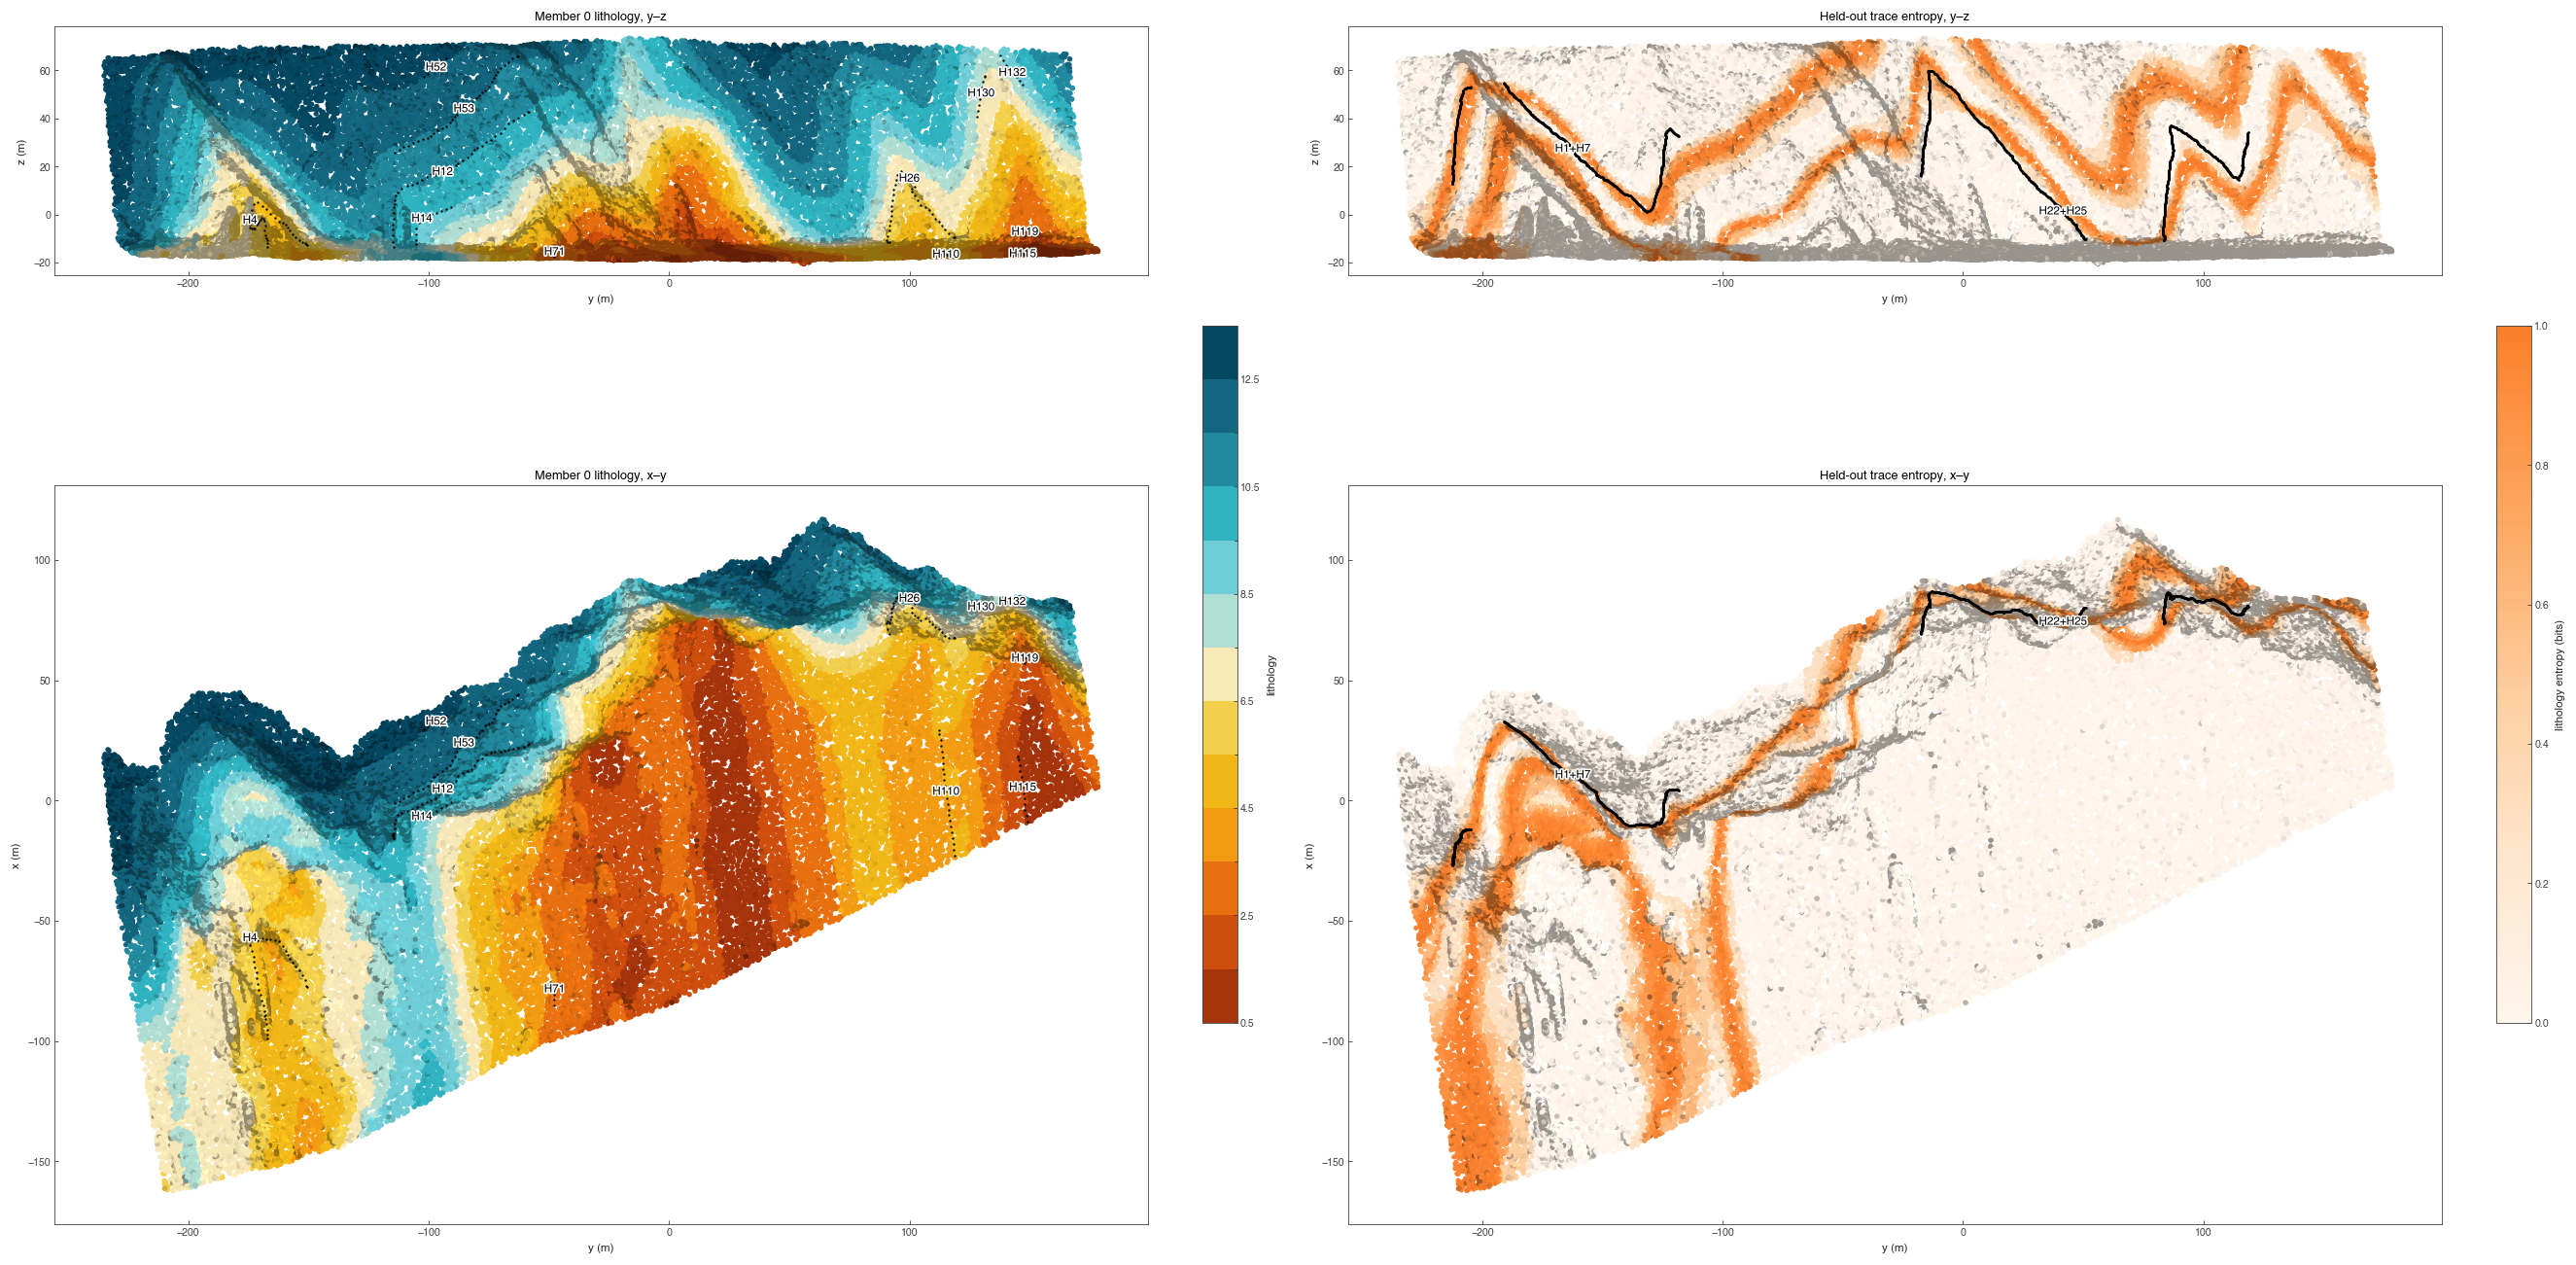

In [8]:
from matplotlib.colors import Normalize
from matplotlib.cm import ScalarMappable
import matplotlib.patheffects as pe
entropy_max = max(0.5, 0.5 * np.ceil(2.0 * float(entropy.max())))
norm_entropy = Normalize(vmin=0.0, vmax=entropy_max)
cmap_litho, norm_litho = figstyle.litho_cmap(np.unique(lithology_member))


def _relief(depth, u, v, cell=0.1):
    """Hillshade from the slope of ``depth`` across the plotted plane. Flat is 1."""
    from scipy.ndimage import distance_transform_edt, gaussian_filter

    depth, u, v = np.asarray(depth, float), np.asarray(u, float), np.asarray(v, float)
    nu = int((u.max() - u.min()) / cell) + 1
    nv = int((v.max() - v.min()) / cell) + 1
    ui = np.clip(((u - u.min()) / cell).astype(int), 0, nu - 1)
    vi = np.clip(((v - v.min()) / cell).astype(int), 0, nv - 1)
    acc = np.zeros((nv, nu))
    count = np.zeros((nv, nu))
    np.add.at(acc, (vi, ui), depth)
    np.add.at(count, (vi, ui), 1.0)
    grid = np.full((nv, nu), np.nan)
    hit = count > 0
    grid[hit] = acc[hit] / count[hit]
    if not hit.all():
        grid = grid[tuple(distance_transform_edt(~hit, return_distances=False, return_indices=True))]
    grid = gaussian_filter(grid, 1.0)
    d_dv, d_du = np.gradient(grid, cell)
    lx, ly, lz = 0.4, 0.5, 1.0
    lx, ly, lz = np.array([lx, ly, lz]) / np.linalg.norm([lx, ly, lz])
    lambert = ((-d_du) * lx + (-d_dv) * ly + lz) / np.sqrt(d_du ** 2 + d_dv ** 2 + 1.0)
    gain = 1.0 + 0.8 * (lambert / lz - 1.0)
    return np.clip(gain, 0.6, 2.0)[vi, ui]
span = np.ptp(cloud_xyz, axis=0)
fig, axs = plt.subplots(
    2, 2, figsize=(22, 12 * (span[2] / span[1] + span[0] / span[1]) + 1.2),
    height_ratios=(span[2], span[0]), constrained_layout=True,
)
views = (((1, 2), np.argsort(-cloud_xyz[:, 0]), "y–z"), ((1, 0), np.argsort(cloud_xyz[:, 2]), "x–y"))
columns = (
    (lithology_member, cmap_litho, norm_litho, "Member 0 lithology"),
    (entropy, figstyle.entropy_cmap(), norm_entropy, "Held-out trace entropy"),
)
overlays = ((spread_names, spread_traces), (heldout_names, heldout))
scatters = []
for row, ((i, j), draw_order, view) in enumerate(views):
    depth_axis = ({0, 1, 2} - {i, j}).pop()
    light = _relief(cloud_xyz[:, depth_axis], cloud_xyz[:, i], cloud_xyz[:, j])
    for col, (values, cmap, norm, title) in enumerate(columns):
        ax = axs[row, col]
        rgba = np.array(cmap(norm(np.asarray(values))), dtype=float, copy=True)
        rgba[..., :3] *= light[:, None]
        ax.scatter(cloud_xyz[draw_order, i], cloud_xyz[draw_order, j], c=np.clip(rgba, 0.0, 1.0)[draw_order],
                   s=10, linewidths=0, rasterized=True)
        for name, t in zip(*overlays[col]):
            ax.scatter(t[:, i], t[:, j], s=2, color="k", linewidths=0, zorder=3)
            mid = t[len(t) // 2]
            ax.text(mid[i], mid[j], name, color="k", fontsize=7, ha="center", va="center",
                    path_effects=[pe.withStroke(linewidth=2, foreground="white")], zorder=4)
        ax.set_aspect("equal")
        ax.set(xlabel=f"{'xyz'[i]} (m)", ylabel=f"{'xyz'[j]} (m)", title=f"{title}, {view}")
        if row == 0:
            mappable = ScalarMappable(norm=norm, cmap=cmap)
            mappable.set_array(np.asarray(values))
            scatters.append(mappable)
fig.colorbar(scatters[0], ax=axs[:, 0], shrink=0.5, label="lithology")
fig.colorbar(scatters[1], ax=axs[:, 1], shrink=0.5, label="lithology entropy (bits)")
plt.show()

member_03: H82, H96, H113, H65, H107, H128, H20, H61, H32, H12, H53, H8
member_04: H94, H86, H72, H106, H124, H109, H62, H56, H130, H49, H53, H52
member_19: H95, H86, H37, H117, H55, H17, H63, H21, H45, H31, H27, H8


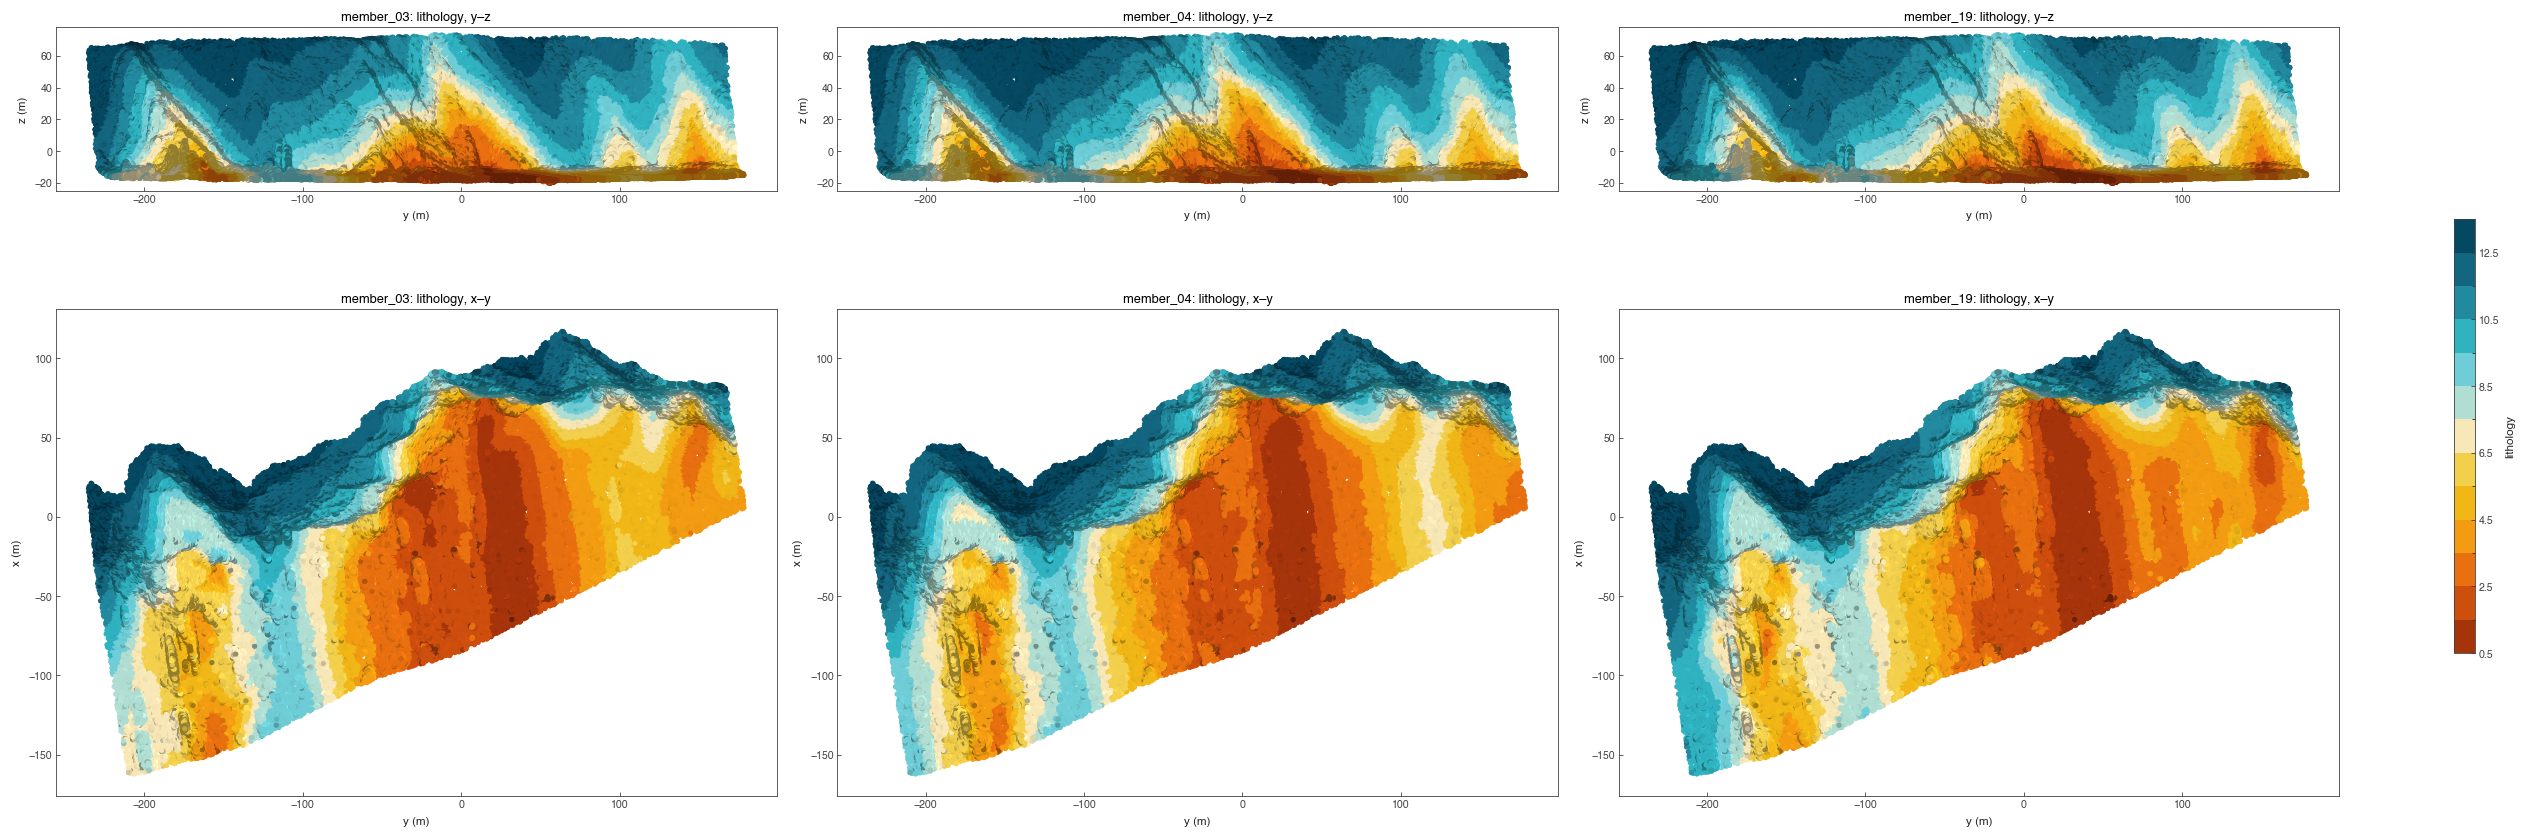

In [18]:
# Quick check (not saved): lithology of any ensemble member, drawn like the member-0 panel above.
# Each member chooses its own N_BEDS traces, spread through the cloud by that member's restored depths
# (the same rule as member 0's), so every panel is that member's best-spread view.
MEMBERS = [3, 4, 19]           # indices into `paths` (0 is member_00): any number, any order

trace_off = np.cumsum([0, *[len(t) for t in traces]])
all_trace_xyz = np.vstack(traces)
lith_pick, bed_names_pick = {}, {}
for k in MEMBERS:
    mdl = loadModel(paths[k])
    phi_c = _scalar(mdl, cloud_xyz)
    phi_t = _scalar(mdl, all_trace_xyz)
    dep = np.array([float(phi_t[trace_off[m]:trace_off[m + 1]].mean()) for m in range(len(traces))])
    pk = _spread(dep, np.quantile(phi_c, (np.arange(N_BEDS) + 0.5) / N_BEDS))
    lith_pick[k] = diagnostics.lithology_from_isovalues(phi_c, dep[pk])
    bed_names_pick[k] = [trace_names[m] for m in pk]
    print(f"{paths[k].stem}: " + ", ".join(bed_names_pick[k]))
    del mdl

cmap_pick, norm_pick = figstyle.litho_cmap(np.unique(np.concatenate(list(lith_pick.values()))))
span = np.ptp(cloud_xyz, axis=0)
views_pick = (((1, 2), np.argsort(-cloud_xyz[:, 0]), "y–z"), ((1, 0), np.argsort(cloud_xyz[:, 2]), "x–y"))
n_m = len(MEMBERS)
fig_pick, axs_pick = plt.subplots(2, n_m, figsize=(7 * n_m, 7 * (span[2] + span[0]) / span[1] + 1.0),
                                  height_ratios=(span[2], span[0]), squeeze=False, constrained_layout=True)
for row, ((i, j), draw_order, view) in enumerate(views_pick):
    light = _relief(cloud_xyz[:, ({0, 1, 2} - {i, j}).pop()], cloud_xyz[:, i], cloud_xyz[:, j])
    for col, k in enumerate(MEMBERS):
        ax_p = axs_pick[row, col]
        rgba = np.array(cmap_pick(norm_pick(lith_pick[k])), dtype=float, copy=True)
        rgba[..., :3] *= light[:, None]
        ax_p.scatter(cloud_xyz[draw_order, i], cloud_xyz[draw_order, j], c=np.clip(rgba, 0.0, 1.0)[draw_order],
                     s=10, linewidths=0, rasterized=True)
        ax_p.set_aspect("equal")
        ax_p.set(xlabel=f"{'xyz'[i]} (m)", ylabel=f"{'xyz'[j]} (m)", title=f"{paths[k].stem}: lithology, {view}")
fig_pick.colorbar(ScalarMappable(norm=norm_pick, cmap=cmap_pick), ax=axs_pick, shrink=0.5, label="lithology")
plt.show()


### Held-out contacts

The test traces are the two pairs 05a held out of the fit and clubbed, H22 with H25
and H0 with H7. Each pair is scored as one trace: whether its points lie on one
surface. Two numbers per pair: the standard deviation of its restored depth (m, in
the restored frame, as for the fitted traces above), and
its **flatness** in the present day: the RMS distance (m) of its points from the one level
surface that fits them best, each point's distance taken with its own gradient,
|ψᵢ − c| / |∇ψᵢ| (`hartland_inputs.trace_flatness`). Rescaling a field does not change it, so
it compares directly with 05c's Surfe fit on the same traces. The fitted traces' flatness
is printed alongside, as the floor the fit reaches on its own data.

In [9]:
def value_and_gradient(points):
    with torch.no_grad():
        v, g = field.value_and_gradient(torch.as_tensor(points, dtype=curlew.dtype, device=curlew.device))
    return v.cpu().numpy().ravel(), g.cpu().numpy()


heldout_names, heldout = hartland_inputs.heldout_traces(data)
with torch.no_grad():
    heldout_sd = np.array([float(field.inverse_map(torch.as_tensor(t, dtype=curlew.dtype, device=curlew.device))
                                 [:, 2].std()) for t in heldout])
flatness = hartland_inputs.trace_flatness(value_and_gradient, traces)
heldout_flatness = hartland_inputs.trace_flatness(value_and_gradient, heldout)
print(f"{len(heldout)} held-out traces ({sum(len(t) for t in heldout)} points): restored-depth sd median "
      f"{np.median(heldout_sd):.2f} m (90th pct {np.percentile(heldout_sd, 90):.2f}, max {heldout_sd.max():.2f}); "
      f"fitted traces median {np.median(depth_std):.2f} m")
print(f"flatness in the present day: held-out median {np.median(heldout_flatness):.2f} m "
      f"(90th pct {np.percentile(heldout_flatness, 90):.2f}, max {heldout_flatness.max():.2f}); "
      f"fitted median {np.median(flatness):.2f} m")
for name, sd, fl in zip(heldout_names, heldout_sd, heldout_flatness):
    print(f"  {name}: restored-depth sd {sd:.2f} m, flatness {fl:.2f} m")

2 held-out traces (2360 points): restored-depth sd median 5.38 m (90th pct 6.12, max 6.31); fitted traces median 0.53 m
flatness in the present day: held-out median 4.37 m (90th pct 4.83, max 4.94); fitted median 0.62 m
  H22+H25: restored-depth sd 6.31 m, flatness 4.94 m
  H1+H7: restored-depth sd 4.46 m, flatness 3.79 m


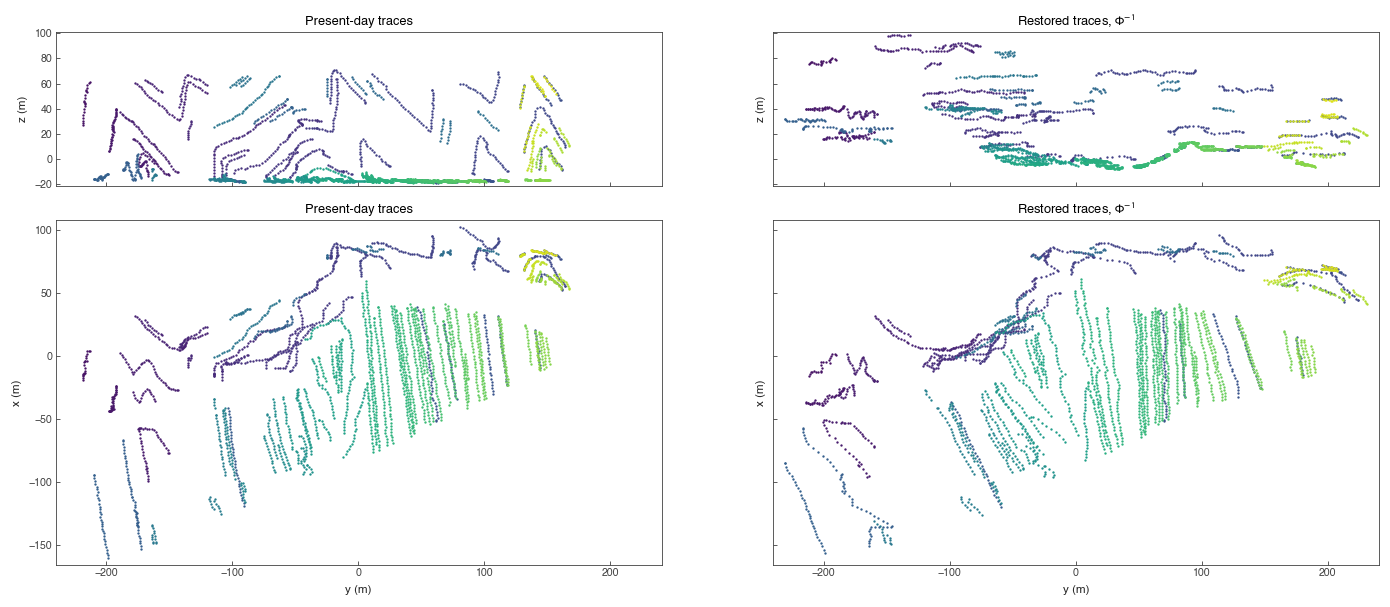

In [10]:
# Quick check (not saved): present-day and restored traces. Section (y–z) above, plan (y–x) below.
# y is shared by every panel; z by the two sections; x by the two plans.
colors = plt.cm.viridis(np.linspace(0.05, 0.95, len(traces)))
pts = np.vstack([*traces, *restored])
span = np.ptp(pts, axis=0)
pad = 0.02 * span
lo, hi = pts.min(0) - pad, pts.max(0) + pad
fig, axs = plt.subplots(
    2, 2, figsize=(12, 6 * (span[2] + span[0]) / max(span[1], 1.0)),
    sharex=True, sharey="row", height_ratios=(span[2], span[0]), constrained_layout=True,
)
panels = (
    (axs[0, 0], traces, 2, "Present-day traces", "z (m)"),
    (axs[0, 1], restored, 2, r"Restored traces, $\Phi^{-1}$", "z (m)"),
    (axs[1, 0], traces, 0, "Present-day traces", "x (m)"),
    (axs[1, 1], restored, 0, r"Restored traces, $\Phi^{-1}$", "x (m)"),
)
for ax, lines, vert, title, ylabel in panels:
    for t, c in zip(lines, colors):
        ax.scatter(t[:, 1], t[:, vert], s=2, color=c, linewidths=0)
    ax.set_aspect("equal")
    ax.set_xlim(lo[1], hi[1])
    ax.set_ylim(lo[vert], hi[vert])
    ax.set_title(title)
    ax.set_ylabel(ylabel)
for ax in axs[1]:
    ax.set_xlabel("y (m)")
plt.show()

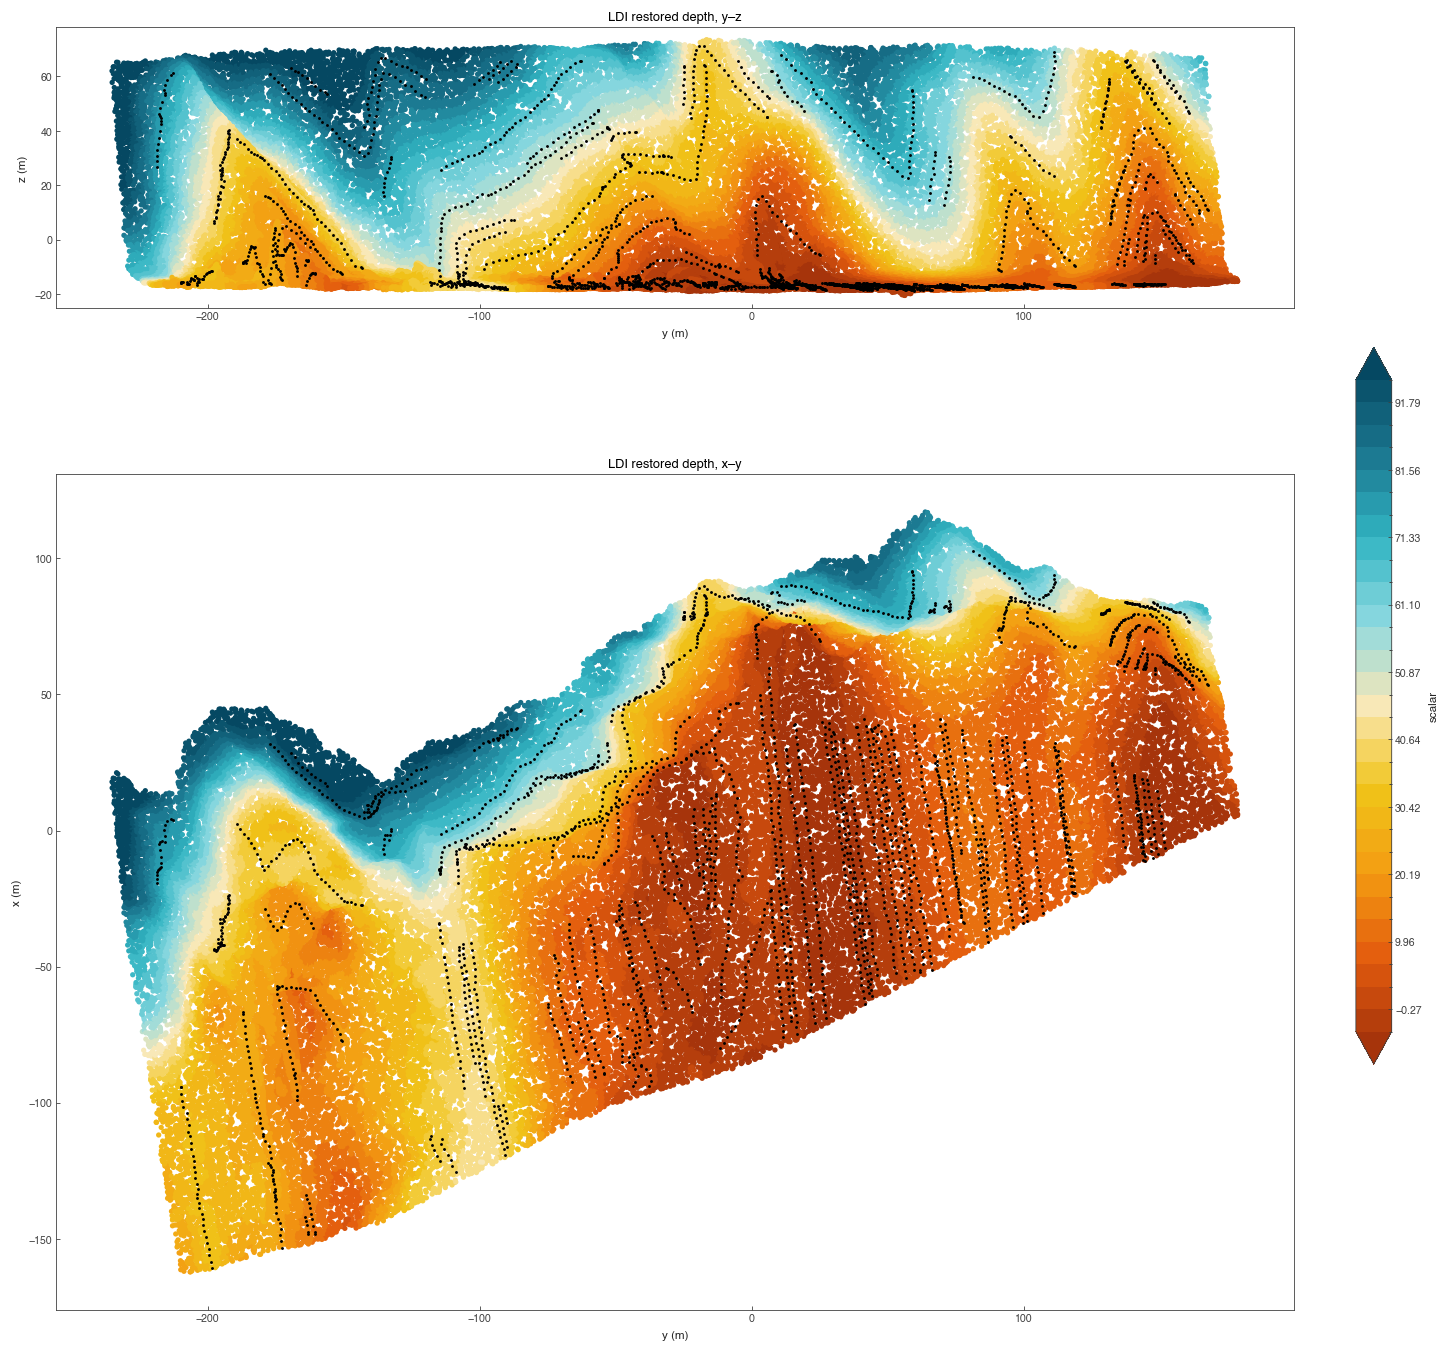

In [11]:
# Quick check (not saved): restored depth on the 05a point cloud, in discrete bands. The band
# edges are the N_BANDS evenly spaced levels between the youngest and oldest trace (as 05d meshes).
N_BANDS = 30
with torch.no_grad():
    phi_cloud = np.concatenate([
        np.asarray(model_restore.predict(torch.as_tensor(chunk, dtype=curlew.dtype, device=curlew.device),
                                         litho=False).scalar).ravel()
        for chunk in np.array_split(cloud_xyz, max(1, len(cloud_xyz) // 50_000))])
band_edges = diagnostics.evenly_spaced_levels(list(event_restore.getIsovalues().values()), N_BANDS)
diagnostics.plot_cloud_scalar(cloud_xyz, phi_cloud, band_edges, lines=traces, title="LDI restored depth", size=10.)
plt.show()

## Save

Restored depth on the grid and each trace's isovalue, the restored traces and
the diagnostics, the comparison numbers, the settings and member 0. The
well-spread beds from the lithology cell (`bed_names`, `bed_isovalues`,
`bed_trace_index`) are copied in here; that cell also writes them to `beds.npz`.
Every member was already saved under `results/ensemble/`.

In [12]:
with torch.no_grad():
    grd = torch.tensor(G.coords(), dtype=curlew.dtype, device=curlew.device)
    phi_grid = G.reshape(np.asarray(model_restore.predict(grd, litho=False).scalar))
iso = {str(k): float(v) for k, v in event_restore.getIsovalues().items()}
np.savez_compressed(
    OUT_DIR / "ldi.npz",
    phi=phi_grid.astype(np.float32), trace_isovalues=np.array([iso[n] for n in trace_names]),
    bed_names=np.asarray(spread_names), bed_isovalues=np.asarray(spread_levels, np.float64),
    bed_trace_index=np.asarray(pick, np.int32),
    restored_depth_mean=depth_mean, restored_depth_std=depth_std,
    **{f"restored_{i}": r for i, r in enumerate(restored)},
    younging_angle=younging, younging_angle_test=younging_test, **diagnostics.pack_critical(crit),
    heldout_names=np.asarray(heldout_names), heldout_depth_std=heldout_sd, flatness=flatness, heldout_flatness=heldout_flatness,
)
comparison = {"extrema": crit.counts, "younging_deg_median": float(np.median(younging)),
              "younging_deg_mean": float(younging.mean()), "fraction_reversed": float(np.mean(cos < 0)),
              "restored_depth_std_median": float(np.median(depth_std)),
              "restored_depth_std_max": float(depth_std.max()),
              "younging_deg_median_cliff": float(np.median(younging_cliff)),
              "younging_deg_median_beach": float(np.median(younging_beach)),
              "younging_deg_median_test": float(np.median(younging_test)),
              "younging_deg_p90_test": float(np.percentile(younging_test, 90)),
              "hinge_bend_deg_median": float(np.median(bend)), "hinge_bend_deg_max": float(bend.max()),
              "heldout_traces": len(heldout), "heldout_depth_std_median": float(np.median(heldout_sd)),
              "flatness_m_median": float(np.median(flatness)),
              "heldout_flatness_m_median": float(np.median(heldout_flatness)),
              "heldout_flatness_m_p90": float(np.percentile(heldout_flatness, 90)),
              "heldout_flatness_m_max": float(heldout_flatness.max())}
(OUT_DIR / "ldi.json").write_text(json.dumps({"comparison": comparison}, indent=1))
(OUT_DIR / "fit_settings.json").write_text(json.dumps(dict(
    seed=SEED, n_ensemble=int(N_ENSEMBLE), ensemble_seeds=[int(s) for s in ENSEMBLE_SEEDS],
    lsr=list(LSR), n_features=N_FEATURES, n_directions=N_DIRECTIONS,
    modes_per_octave=MODES_PER_OCTAVE, band_info=BAND_INFO, n_steps=N_STEPS,
    integrator=INTEGRATOR, epochs=EPOCHS, weights=WEIGHTS,
    energy_biased=ENERGY_BIASED, lr_adam=LR_ADAM, lr_sgd=LR_SGD, amp_momentum=AMP_MOMENTUM, init_std=INIT_STD,
    hinge=hinge.tolist(), hinge_trend_plunge=[axis["trend"], axis["plunge"]],
    pole_wavelength=POLE_WAVELENGTH, anisotropy_scales=[float(s) for s in scale],
    grid_step=list(G.step), pad=PAD
), indent=2))
saveModel(OUT_DIR / "restore.pt", model_restore)
print("wrote inputs.npz, ldi.npz, ldi.json, fit_settings.json, restore.pt to", OUT_DIR)

wrote inputs.npz, ldi.npz, ldi.json, fit_settings.json, restore.pt to results
